<a href="https://colab.research.google.com/github/kalinapeterson12/Project-2-SUPPORT2_Dataset/blob/main/Data_201_Project_2_Decision_Tree_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data 201 Project #2

Kalina Peterson

# Part 1: Introduce the Dataset




The Support2 Dataset, gathered by Professor Frank Harrell in 2022, follows 9105 critically ill patients across the US for a maximum of 5.56 years, or until the patient's death. Each row represents a patient in the study who suffered from one of nine diseases: acute respiratory failure, chronic obstructive pulmonary disease, congestive heart failure, liver disease, coma, colon cancer, lung cancer, multiple organ system failure with malignancy, and multiple organ system failure with sepsis. The features include demographics, clinical data, activities of daily living, hospital expenses and how long the patient remained in the study.

For this project I will be predicting the total number of days from study entry until the patient's death, stored in the variable d.time. I will be filtering specifically for patients with some type of Cancer. There are 47 predictors in this dataset, some of which will be removed during the data cleaning process to prevent redundancy or data leakage.

---

**Citation:** Data from Vanderbilt University Department of Biostatistics, Professor Frank Harrell 2022, https://hbiostat.org/data/ (scroll down to the support data)

**Metadata:** https://archive.ics.uci.edu/dataset/880/support2

**Variable Definitions:** https://archive.ics.uci.edu/dataset/880/support2

### Loading the Dataset

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_PATH = '/content/drive/MyDrive/Data_201/Datasets/support2.csv'   # change this if needed
support2 = pd.read_csv(DATA_PATH)

### Filtering for Death =  1

Officially, my target variable (d.time) is the days of follow up for a patient after entering the study (it counts days spent both inside and outside of the hospital). However, this variable has different meanings based on whether or not the patient died during the study:
 - If death = 1 (the patient died), d.time is the total number of days from study entry until the patient's death (tracked through hospital records or the National Death Index).
  
  - If death = 0 (the patient survived), d.time is the total number of days the patient was observed and known to be alive before the study follow-up period ended.

Essentially, the issue comes from the fact that d.time stops counting both when the patient dies and when the patient is entirely recovered and discharged from the hospital.

So, I need to filter the dataset for patients that died to build an accurate model that can discover patterns and predict how long a patient will survive.

In [5]:
death = support2[(support2['death'] == 1) & (support2['dzclass'] == 'Cancer')]
print(death.shape)
death.head()

(1260, 47)


,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,...,crea,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc
4,42.38498,1,female,0,3,133,Lung Cancer,Cancer,2,11.0,...,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,no(M2 and SIP pres),0.0000
9,85.65594,1,male,0,12,63,Lung Cancer,Cancer,2,12.0,...,1.000000,143.0,7.449219,NaN,NaN,NaN,NaN,7.0,NaN,7.0000
10,42.25897,1,female,0,8,370,Colon Cancer,Cancer,0,11.0,...,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.4948
12,59.20099,1,male,1,13,13,Lung Cancer,Cancer,0,14.0,...,1.099854,136.0,NaN,NaN,NaN,NaN,1.0,1.0,<2 mo. follow-up,1.0000
16,58.82300,1,female,0,7,503,Lung Cancer,Cancer,1,12.0,...,0.799927,134.0,NaN,NaN,NaN,NaN,2.0,0.0,NaN,0.0000


**Variables/Predictors in the data**



In [6]:
# All 47 Columns in the dataset
death.columns

Index(['age', 'death', 'sex', 'hospdead', 'slos', 'd.time', 'dzgroup',
       'dzclass', 'num.co', 'edu', 'income', 'scoma', 'charges', 'totcst',
       'totmcst', 'avtisst', 'race', 'sps', 'aps', 'surv2m', 'surv6m', 'hday',
       'diabetes', 'dementia', 'ca', 'prg2m', 'prg6m', 'dnr', 'dnrday',
       'meanbp', 'wblc', 'hrt', 'resp', 'temp', 'pafi', 'alb', 'bili', 'crea',
       'sod', 'ph', 'glucose', 'bun', 'urine', 'adlp', 'adls', 'sfdm2',
       'adlsc'],
      dtype='object')

### Dealing with Missing Values

Due to the high percentage of missing values in the clinical data, the original reseracher recomemnded inputing certain values for some of the physiologic variables (https://hbiostat.org/data/repo/supportdesc, Professor Frank Harrell).

The following default values have been found to be useful in imputing missing baseline physiologic data:
- Serum albumin (alb):	3.5
- PaO2/FiO2 ratio (pafi): 	333.3
- Bilirubin (bili):	1.01
- Creatinine (crea):	1.01
- bun:	6.51
- White blood count (wblc):	9 (thousands)
- Urine output (urine):	2502

I will be using these fill-in values for missing data.


In [7]:
death.isna().sum()

,0
age,0
death,0
sex,0
hospdead,0
slos,0
d.time,0
dzgroup,0
dzclass,0
num.co,0
edu,216


In [8]:
# Filling in NAs with Values Recommended by researcher
# view values here: https://hbiostat.org/data/repo/supportdesc
fill_values = {'alb': 3.5,
               'pafi': 333.3,
               'bili': 1.01,
               'crea': 1.01,
               'bun': 6.51,
               'wblc': 9,
               'urine': 2502}
death = death.fillna(fill_values)

## Removing Unnecessary or Data Leakage Variables

There are 47 variables in the data. Many of these contain similar information, are summarized within other variables, or may leak information about how long the patient survived. As such, there are many columns I need to remove.

**Redundant columns:** (information provided is summarized or given in another variable)

*   adlp and adls information (the number of daily living activities the patient can complete independently) is combined in adlsc
*   ph and glucose have too many na's. overall measure of health is given in sps

**Columns that leak target information:**
 * prg2m and prg6m are human guesses at d.time
  *  medical cost data (totcst, totmdct, and charges) MUST be removed, because cost is related to how long a patient will stay at the hospital. Medical expenses aren't calculated until d.time is complete
  * Duration of hospital stay = remove slos and hospdead - the longer they stayed at the hospital the higher the d.time
  * sps, aps - values are predicted by the researcher's model, and are not actual patient data (researcher recommended removal when building models)
  * remove advisst - contains information from days 3-25 in the study
  * And, of course, I will remove d.time from training data later on, during the train-test split.

Suggestion from original researcher, Frank Harrell: "To develop models without using findings from previous models, be sure not to use aps, sps, surv2m, surv6m as predictors. You also will probably not want to use prg2m, prg6m, dnr, dnrday."(https://hbiostat.org/data/repo/supportdesc)

In [9]:
cols_to_drop = [
    # contain death outcomes, redundant or leaks information
    "death", "hospdead", "sfdm2",
    # leaks how long the patient lived
    "slos", "avtisst",
    # medical costs leak how long the patient lived
    "totcst", "totmcst", "charges",
    # Prognostic guesses made by humans, contain information can't get from numbers. Surv made by a model.
    "prg2m", "prg6m", "surv2m", "surv6m", "dnr",
    # DNR's given on a certian day - shows they lived htat long
    "dnrday",
    # redundant - information included in adlsc
    "adlp", "adls",
    # too many na's, other clinical data is included
    "ph", "glucose",
    # similar information containted in income
    'edu',
    # stays constant: filtered for dzclass = Cancer - dzclass is unnecessary
    "dzclass",
    #remove sps, aps - reserarcher's model predictions for physiology score, not actual patient data
    "sps", 'aps'
    ]

death1 = death.drop(columns=cols_to_drop)
print(death1.shape)
death1.isna().sum()

(1260, 25)


,0
age,0
sex,0
d.time,0
dzgroup,0
num.co,0
income,415
scoma,0
race,6
hday,0
diabetes,0


In [13]:
# Removing the remaining NA values
death2 = death1.copy().dropna()
print(death2.shape)
death2.head()

(845, 25)


,age,sex,d.time,dzgroup,num.co,income,scoma,race,hday,diabetes,...,resp,temp,pafi,alb,bili,crea,sod,bun,urine,adlsc
4,42.38498,female,133,Lung Cancer,2,under $11k,0.0,white,1,0,...,32.0,35.00000,333.3,3.500000,1.010000,0.799927,139.0,6.51,2502.0,0.000000
10,42.25897,female,370,Colon Cancer,0,$25-$50k,0.0,hispanic,1,0,...,20.0,38.19531,333.3,4.699219,0.199982,0.799927,139.0,6.51,2502.0,0.494800
16,58.82300,female,503,Lung Cancer,1,>$50k,0.0,white,1,0,...,20.0,37.19531,333.3,4.299805,0.199982,0.799927,134.0,6.51,2502.0,0.000000
21,68.25494,male,227,Lung Cancer,0,>$50k,0.0,white,1,0,...,20.0,36.50000,333.3,4.299805,0.299988,1.199951,138.0,6.51,2502.0,0.000000
24,50.72400,female,817,Lung Cancer,0,$25-$50k,0.0,asian,1,0,...,24.0,37.39844,333.3,3.500000,1.010000,0.899902,141.0,6.51,2502.0,2.065918


## Categorical Variable Encoding
I will encode two of the categorical variables (sex and income) ordinally. Sex can become a binary variable, and income has an ordinal value (under $11k mapped to 0, over 50k mapped to 5).

The rest of the categorical variables, like cancer type (dzgroup) and race, will be encoded using OneHotEncoder during preprocessing for a Decision Tree or Random Forest.

In [14]:
# Ordinal encoding: Income and gender
death2['sex_encoded'] =  death2['sex'].map({'male': 0, 'female': 1}) # Becomes binary
death2['income_encoded'] = death2['income'].map({ #assigns encoded levels to income
    'under $11k':0,
    '$11-25k':1,
    '$25-$50k': 2,
    '>$50k':3})
death3 = death2.drop(columns=['sex', 'income'])
death3.head()

,age,d.time,dzgroup,num.co,scoma,race,hday,diabetes,dementia,ca,...,pafi,alb,bili,crea,sod,bun,urine,adlsc,sex_encoded,income_encoded
4,42.38498,133,Lung Cancer,2,0.0,white,1,0,0,metastatic,...,333.3,3.500000,1.010000,0.799927,139.0,6.51,2502.0,0.000000,1,0.0
10,42.25897,370,Colon Cancer,0,0.0,hispanic,1,0,0,metastatic,...,333.3,4.699219,0.199982,0.799927,139.0,6.51,2502.0,0.494800,1,2.0
16,58.82300,503,Lung Cancer,1,0.0,white,1,0,0,metastatic,...,333.3,4.299805,0.199982,0.799927,134.0,6.51,2502.0,0.000000,1,3.0
21,68.25494,227,Lung Cancer,0,0.0,white,1,0,0,metastatic,...,333.3,4.299805,0.299988,1.199951,138.0,6.51,2502.0,0.000000,0,3.0
24,50.72400,817,Lung Cancer,0,0.0,asian,1,0,0,metastatic,...,333.3,3.500000,1.010000,0.899902,141.0,6.51,2502.0,2.065918,1,2.0


# Part 2: Prepare Data & Fit Decision Tree

## OneHot Encoding & Scaling Preprocesser



Now I need to build a preprocessing function that will encode my categorical variables before passing them through the decision tree, because the decision trees cannot split string values.

The preprocessor will also scale my numerical features, which is extremely important because some measurements (like creatine levels) are less than 1, while other values (like urine output) are given in the thousands. I need to scale my numerical predictors to ensure they don't drown each other out in the model.

In [21]:
death3.columns

Index(['age', 'd.time', 'dzgroup', 'num.co', 'scoma', 'race', 'hday',
       'diabetes', 'dementia', 'ca', 'meanbp', 'wblc', 'hrt', 'resp', 'temp',
       'pafi', 'alb', 'bili', 'crea', 'sod', 'bun', 'urine', 'adlsc',
       'sex_encoded', 'income_encoded'],
      dtype='object')

In [22]:
# Defining categorical and numeric features

numeric_features = ['age', 'num.co', 'scoma', 'hday', 'meanbp', 'wblc', 'hrt', 'resp', 'temp',
                    'pafi', 'alb', 'bili', 'crea', 'sod', 'bun', 'urine', 'adlsc']

categorical_features = [
     'dzgroup', 'race', 'diabetes', 'dementia', 'ca', 'sex_encoded', 'income_encoded'
]


# Build preprocessing steps
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Combine preprocessing with decision tree
tree = make_pipeline(
    preprocess,
    DecisionTreeRegressor(random_state= 50) # no maximum depth, grow the full tree
)

## Splitting the Data & Fitting the Tree

In [23]:
# Split into training and testing
X = death3.drop(columns='d.time')   # dropping the predictor
y = death3['d.time']                # How long the patient survived


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30, # 70% training data, 30% test
    random_state= 50
)

# Fit preprocessing and model
tree.fit(X_train, y_train)

# Get model predictions
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

# Evaluate
train_rmse = root_mean_squared_error(y_train, y_train_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)

print('Training RMSE:     ', round(train_rmse, 3))
print('Test RMSE:         ', round(test_rmse, 3))

Training RMSE:      0.0
Test RMSE:          265.782


Since I grew a tree with no maximum depth, it kept growing until all the leaves were pure and thus overfitted on the training data. Because of this, the squared error 0 on the training data but much higher on the testing data. A tree with a maximum depth would perform better because it would learn from the training data rather than simply memorizing it.


# Part 3: Build and Compare a Random Forest

The results from a single Decision Tree are unstable, and sensitive to small changes in the training data. Creating a Random Forest and combining the scores from multiple unique trees will lead to better results.

The Random Forest uses a method called ensemble learning. It gives a different data sample to each tree, and the errors in each individual tree are cancelled out when the trees' scores are combined. Thus, the Random Forest is more stable, has reduced variance, and a lower mean squared error.


## Building a Random Forest

In [26]:
# Making a pipeline with the preprocessing function
forest1 = make_pipeline(
    preprocess,
    RandomForestRegressor(n_estimators=100, random_state=50, n_jobs = -1)
)

forest1.fit(X_train, y_train)

# Get model predictions
y_train_pred_forest = forest1.predict(X_train)
y_test_pred_forest = forest1.predict(X_test)

# Evaluate RMSE
forest_train_rmse = root_mean_squared_error(y_train, y_train_pred_forest)
forest_test_rmse = root_mean_squared_error(y_test, y_test_pred_forest)

print('Forest Training Set RMSE:     ', round(forest_train_rmse, 3))
print('Forest Test Set RMSE:         ', round(forest_test_rmse, 3))

Forest Training Set RMSE:      82.083
Forest Test Set RMSE:          206.919


## Comparing Models: Decision Tree vs Random Forest
|            |   **Training RMSE** |  **Test RMSE** |
| -------------- | -------------: | -------------: |
| Decision Tree  | 0.0 | 265.782 |
| Random Forest  | 82.083 | 206.919 |

The random forest is significantly better at predicting unseen values. Both the Decison Tree and the Random Forest have a low training RMSE because the trees were allowed to grow fully. But, the Random Forest had a lower error on the testing data than the Decision Tree because it used ensemble learning.




# Part 4: Investigating Random Forest Parameters

The Random Forest trees are still allowed to grow fully, overfitting on the training data. Additionally, adding more trees to our random forest will reduce variance. So, tuning the maximum tree depth and the number of estimators will help create a better model.




## Tuning Number of Estimators

I will be experimenting with 3 different estimator values: 10, 50 & 100. Cross validation will tune the parameters and determine which of these values yields the best model.

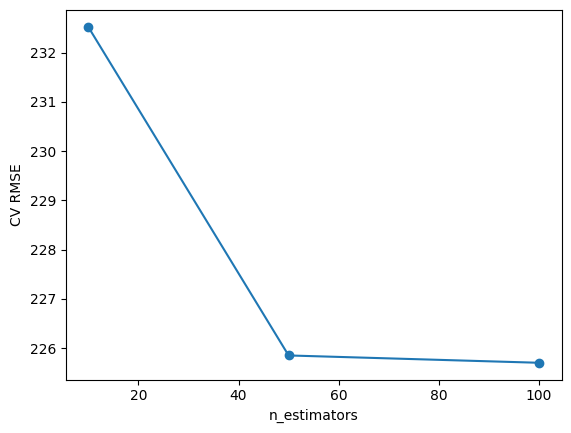

Best max_depth: 100
Test RMSE:              206.919


In [27]:
# Number of estimators
n_estimators = [10, 50, 100]
cv_rmse = []

# for loop to preprocess and build model for each value in n_estimators
for n in n_estimators:
    m = make_pipeline(
        preprocess,
        RandomForestRegressor(n_estimators=n, random_state=50, n_jobs=-1)
    )
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

# plot n_estimators vs RMSE
plt.plot(n_estimators, cv_rmse, marker='o')
plt.xlabel('n_estimators'); plt.ylabel('CV RMSE'); plt.show()

# extracting best n_value & building tree
best_n = list(n_estimators)[int(np.argmin(cv_rmse))]
best_forest_estimator = make_pipeline(
        preprocess,
        RandomForestRegressor(n_estimators=best_n, random_state=50, n_jobs=-1)).fit(X_train, y_train)

# Evaluate RMSE score
def rmse(model): return np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
print('Best max_depth:', best_n)
print('Test RMSE:             ', round(rmse(best_forest_estimator), 3))

50 trees was significantly better than using only 10, and the using 100 trees performed even better. It yielded the lowest RMSE of 206.

Adding more trees could further lower the score. However, since there was a minimal increase in RMSE from 50 trees to 100, and due to the computational demand of creating more trees, using 100 trees in our random forest should be sufficent.

## Tuning Maximum Depth

To tune maximum tree depth, I will experiment with 4 different depth values: 2, 4, 8 and 12. In this case, a very low max_depth would cause the tree to underfit, not growing enough to learn from the data, and a high max_depth would cause the tree to overfit and learn every detail from the training data. The best maximum depth will likely be somewhere in the middle, 4 or 8, that allows the tree to learn without memorizing information.

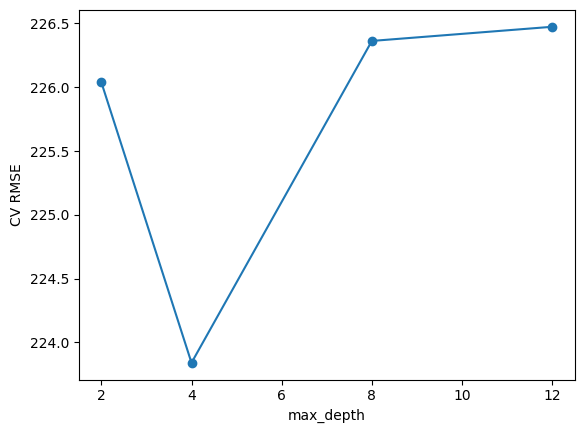

Best max_depth: 4
Test RMSE:              205.172


In [29]:
# depth values to test
depths = [2, 4, 8, 12]
cv_rmse = []

# for loop creating random forest for each depth value (with n_estimators = 100)
for d in depths:
    m = make_pipeline(
        preprocess,
        RandomForestRegressor(max_depth = d, n_estimators=100, random_state=50, n_jobs=-1)
    )
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

# plot of depths vs RMSE
plt.plot(depths, cv_rmse, marker='o')
plt.xlabel('max_depth'); plt.ylabel('CV RMSE'); plt.show()

# extracting best depth value & building random forest
best_d = list(depths)[int(np.argmin(cv_rmse))]
best_forest_depth = make_pipeline(
        preprocess,
        RandomForestRegressor(max_depth = best_d, n_estimators=100, random_state=50, n_jobs=-1)).fit(X_train, y_train)

# Evaluating RMSE of best model
def rmse(model): return np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
print('Best max_depth:', best_d)
print('Test RMSE:             ', round(rmse(best_forest_depth), 3))


The best depth value was 4. It had the lowest cross validation rmse of 205.17. As we see in the graph above, more trees led to more overfitting and worse performance on the testing data.

## Final Random Forest

Now I will build a final Random Forest, combining the best parameters from tuning the number of estimators and the maximum depth. In the final model, n_estimators will be 100 and the maximum depth will be 4.

In [30]:
best_rf = make_pipeline(
    preprocess,
    RandomForestRegressor(max_depth = 4, n_estimators = 100, random_state = 50, n_jobs = -1))
best_rf.fit(X_train, y_train)

def rmse(model): return np.sqrt(mean_squared_error(y_test, model.predict(X_test)))

print('Test RMSE:             ', round(rmse(best_rf), 3))

Test RMSE:              205.172


The best Random Forest Model had a RMSE of 205.17. This value is the same as the best max_depth model because the n_estimators in that model was set to 100 (the default).

# Part 5: Feature Importance

## Feature Importance Graph

Now I need to extract what features from the final Random Forest. What predictors were used in the best model?

In [38]:
# extracting names and feature importance
feature_names = best_rf.named_steps['columntransformer'].get_feature_names_out() #use named_steps to reach inside pipeline
feature_imp = best_rf.named_steps['randomforestregressor'].feature_importances_

# creating a dataframe of feature importances
importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_imp
})

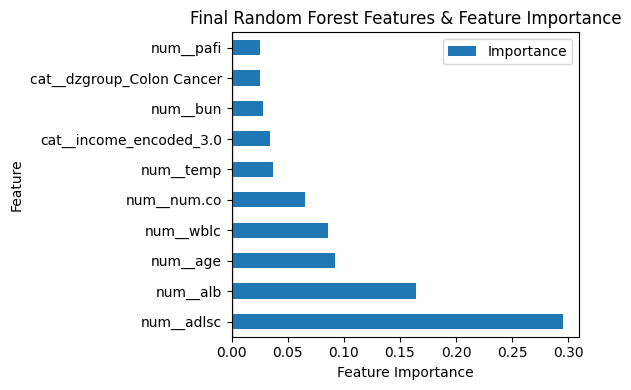

In [37]:
# getting the top 10 data values
top10 = importances.sort_values('Importance', ascending = False).head(10)

# creating a bar chart\
plot_fi = top10.set_index('Feature')[['Importance']]
plot_fi.plot(kind='barh', figsize=(6, 4))
plt.axvline(0, linewidth=1)
plt.xlabel('Feature Importance')
plt.title('Final Random Forest Features & Feature Importance')
plt.tight_layout()
plt.show()

## Top 10 Feature Definitions
 - **pafi** - The ratio of arterial oxygen partial pressure (PaO2 in mmHg) to fractional inspired oxygen (FiO2 expressed as a fraction)
 -  **dzgroup_Colon Cancer** - whether or not the cancer type was Colon Cancer
 - **bun** - Blood urea nitrogen levels
 - **income_encoded_3.0** - whether or not the patient had an income greater than $50,000
 -  **temp** - patient's measured temperature in Celcius
 - **num.co** - number of diseases the patient was experiencing simultaneously
 - **wblc** - counts of white blood cells (in thousands) measured at day 3
 - **age** - age of the patient
 - **alb** - patient serum albumin levels
 - **adlsc** - the number of Activities of Daily Living the patient can complete independently (out of 6), as reported either by the patient or surrogate

# Conclusion

The three most important predictors were age of the patient, the patients serum albumin levels, and the number of Activities of Daily Living the patient can complete independently (out of 6). With these variables I created a Random Forest that predicted how long a patient would survive (d.time). The Random Forest model worked best with a maximum depth of 4 and with 100 trees in the model, and far surpassed the original, single Decision Tree Model. Tuning the two paramaters showed that a lower maximum depth is better, as long is the tree is still allowed to grow enough that it can learn, and a higher number of estimators reduces variance in the tree (making it more stable) but is more computationally expensive. One limitation of my analysis was the high number of missing values, I would've liked to see if glucose or ph levels in the patient had any significance in how long the patient survived. Additionally, one of the three most important predictors, serum albumin levels, had missing values that were replaced with a value of 3.5. I wonder if this influenced its use in the model.

# Sources
UCI Machine Learning Repository. (n.d.). https://archive.ics.uci.edu/dataset/880/support2

SUPPORT. (n.d.). https://hbiostat.org/data/repo/supportdesc

Vanderbilt Department of Biostatistics. (n.d.). Datasets. https://hbiostat.org/data/

